# Braude College of Engineering - Data Mining & Machine Learning (61761)
# Lab 4: K-Means Clustering, Gaussian Mixture Models (EM) & Cluster Validation

### 1. Imports

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.datasets import load_wine
from sklearn.metrics import silhouette_score
from sklearn.mixture import GaussianMixture

### 2. Dataset Loading

In [2]:
# Load dataset features (unsupervised setting: targets are ignored during fitting)
wine = load_wine(as_frame=True)
df_features = wine.data[["alcohol", "flavanoids", "color_intensity"]].copy()

print("Features subset shape:", df_features.shape)
display(df_features.head())

Features subset shape: (178, 3)


,alcohol,flavanoids,color_intensity
0,14.23,3.06,5.64
1,13.20,2.76,4.38
2,13.16,3.24,5.68
3,14.37,3.49,7.80
4,13.24,2.69,4.32


### 3. Baseline K-Means & Inertia Demo

In [3]:
# Fit baseline K-Means with K=3
kmeans_demo = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_demo.fit(df_features)

print(f"Converged in {kmeans_demo.n_iter_} iterations")
print(f"Inertia (Sum of squared distances): {kmeans_demo.inertia_:.2f}")

# Compute baseline silhouette score
sil_demo = silhouette_score(df_features, kmeans_demo.labels_)
print(f"Baseline Silhouette Score (K=3): {sil_demo:.4f}")

Converged in 6 iterations
Inertia (Sum of squared distances): 346.83
Baseline Silhouette Score (K=3): 0.4315


### 4. GMM Demo (Soft vs. Hard Assignment)

In [4]:
# Fit Gaussian Mixture Model with 3 components
gmm_demo = GaussianMixture(n_components=3, random_state=42)
gmm_demo.fit(df_features)

# Inspect soft probabilities for the first 3 samples
sample_probs = gmm_demo.predict_proba(df_features[:3])
print("Membership probabilities for first 3 samples:")
np.set_printoptions(suppress=True, precision=4)
print(np.round(sample_probs, 5))

Membership probabilities for first 3 samples:
[[1.     0.     0.    ]
 [0.9999 0.     0.0001]
 [1.     0.     0.    ]]


### 5. 2D Cluster Visualisation Demo

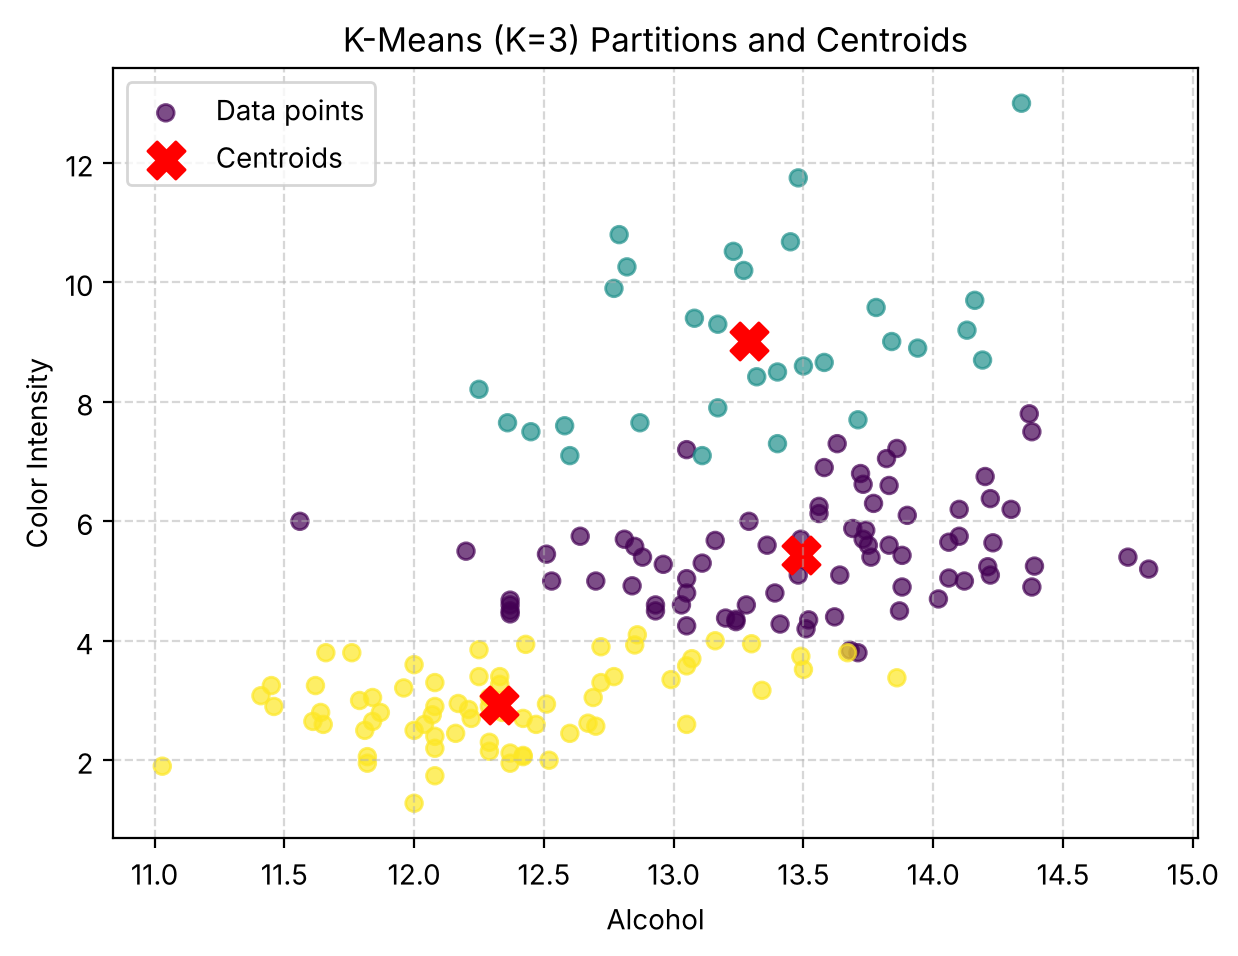

In [5]:
plt.figure(figsize=(7, 5))
plt.scatter(
    df_features["alcohol"],
    df_features["color_intensity"],
    c=kmeans_demo.labels_,
    cmap="viridis",
    alpha=0.7,
    label="Data points"
)

# Plot cluster centers (projected on alcohol vs color_intensity)
centers = kmeans_demo.cluster_centers_
plt.scatter(
    centers[:, 0],
    centers[:, 2],
    c="red",
    s=180,
    marker="X",
    label="Centroids"
)

plt.xlabel("Alcohol")
plt.ylabel("Color Intensity")
plt.title("K-Means (K=3) Partitions and Centroids")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

## PART B: Independent Student Tasks

### Task 1 & Task 2: Elbow Method & Silhouette Score Loop
1. Iterate over K values: `[2, 3, 4, 5, 6, 7, 8]`.
2. For each K, fit a KMeans model (using `random_state=42`, `n_init=10`).
3. Record both the `inertia_` and the `silhouette_score`.
4. Display a summary DataFrame containing K, Inertia, and Silhouette Score.

In [6]:
# TODO: Loop through K values, compute inertia and silhouette scores, and display the table
K_values = [2, 3, 4, 5, 6, 7, 8]
res = []
for K in K_values:
    km = KMeans(n_clusters=K, random_state=42, n_init=10)
    km.fit(df_features)

    res.append({
        "K": K,
        "Inertia": km.inertia_,
        "Silhouette Score": silhouette_score(df_features, km.labels_)
    })

df_results = pd.DataFrame(res)
display(df_results.round(4))

,K,Inertia,Silhouette Score
0,2,588.3989,0.4748
1,3,346.8319,0.4315
2,4,258.9733,0.4139
3,5,201.2866,0.4368
4,6,160.2698,0.4387
5,7,134.7053,0.4270
6,8,122.7386,0.3619


**Observation for Tasks 1 & 2:**  
*Observed Elbow point (K):*  
*K with highest Silhouette Score:* K = 2

### Task 3: GMM Soft Assignment & Uncertainty Analysis
1. Fit a `GaussianMixture` model using the optimal K identified in Task 2 (`random_state=42`).
2. Extract predicted probabilities for all samples using `.predict_proba()`.
3. Identify the sample with the highest classification uncertainty (the sample with the lowest maximum probability).
4. Print the sample's DataFrame index and its cluster probability distribution.

In [7]:
# TODO: Fit GMM with optimal K, find the most uncertain sample, and print its details
k_optimal = 2
gmm = GaussianMixture(n_components=k_optimal, random_state=42)
gmm.fit(df_features)

sample_probs = gmm.predict_proba(df_features)

max_probs = sample_probs.max(axis=1)
pos = max_probs.argmin()
idx = df_features.index[pos]

print(f"Most uncertain sample index: {idx}")
print(f"Probability vector: {np.round(sample_probs[pos], 4)}")
print(f"Max probability: {max_probs[pos]:.4f}")

Most uncertain sample index: 60
Probability vector: [0.4349 0.5651]
Max probability: 0.5651


### Task 4: Conceptual Understanding
**Question:** Why does K-Means inertia strictly decrease as K increases, and why can't we simply pick the K value that minimizes inertia?  
*(Write your 1-2 sentence answer below)*

**Answer for Task 4:** As K increases, there are more centroids, so every point can sit closer to one of them and the sum of squared distances (the inertia) goes down. In the extreme case, with one cluster per point, the inertia reaches 0. That is why we cannot simply pick the K with the lowest inertia: it would always choose the largest K without finding any real structure in the data. Instead, we look for the point where adding more clusters stops helping much (the elbow), or we use a metric such as the silhouette score.

ככל שמוסיפים עוד אשכולות, יש יותר מרכזים, ולכן כל נקודה יכולה להיות קרובה יותר למרכז כלשהו, וסכום המרחקים בריבוע (ה-inertia) הולך וקטן. בקצה, כשיש אשכול לכל נקודה, ה-inertia מגיע ל-0. לכן אי אפשר פשוט לבחור את ה-K עם ה-inertia הנמוך ביותר: זה תמיד ייתן את ה-K הגדול ביותר בלי שנמצא מבנה אמיתי בנתונים. במקום זה מחפשים את הנקודה שבה הוספת אשכולות כבר לא משפרת הרבה (ה-elbow), או משתמשים במדד כמו silhouette score.